<a href="https://colab.research.google.com/github/Nastia-Pyrohova/BlackSeaAISchool_safety_tutorial/blob/main/BlackSeaAISchool_safety_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Watermarking LLM text: a hands-on tutorial

*AI Safety and Alignment · Black Sea AI School · ~10–15 minutes*

In the lecture we saw the **green list watermark** (Kirchenbauer et al., 2023). In this notebook we build it from scratch in ~20 lines, watch it work token by token, and then poke at its limits.

**What we will do**

1. Load a small open model
2. Write the watermark as a `LogitsProcessor`
3. Generate text with and without the watermark and *see* the green tokens
4. Detect the watermark with a z-test
5. Explore the trade-offs: watermark strength, text length, edits and paraphrasing
6. Use the built-in watermark in 🤗 `transformers`

Just run the cells top to bottom — everything is explained along the way. A GPU runtime (*Runtime → Change runtime type → T4*) makes generation faster, but CPU works too.

## 0 · Setup

In [ ]:
!pip -q install -U transformers accelerate

import math, random
import torch
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from transformers import AutoTokenizer, AutoModelForCausalLM, LogitsProcessor, LogitsProcessorList

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0); random.seed(0)
print("device:", device)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 44.1 MB/s eta 0:00:00
device: cuda


We use **Qwen2.5-0.5B-Instruct**: small enough to run anywhere, good enough to write coherent paragraphs.

In [ ]:
MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=torch.float16 if device == "cuda" else torch.float32).to(device)
model.eval()

def chat_prompt(text):
    # wrap a user message in the model's chat template
    msgs = [{"role": "user", "content": text}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

print("vocabulary size:", model.config.vocab_size)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

vocabulary size: 151936


## 1 · The idea in one picture

At every step the model produces a score (logit) for each token in the vocabulary. The watermark nudges these scores:

1. Take the **previous token** and hash it together with a **secret key**.
2. Use the hash as a random seed to split the vocabulary: a fraction **γ** of tokens is **green**, the rest is red.
3. Add a small bonus **δ** to the logits of all green tokens.
4. Sample as usual.

When the model is unsure between several good words, the bonus tips it towards a green one. When one word is clearly right, δ is too small to change it — so the text stays fluent.

Without the key, the green lists look random. With the key, anyone can recompute them and count how many tokens are green.

## 2 · The watermark in ~20 lines

`transformers` lets us plug a `LogitsProcessor` into generation. It receives the tokens so far and the scores for the next token, and may change the scores. That is exactly where the watermark lives.

In [ ]:
class GreenListWatermark(LogitsProcessor):
    def __init__(self, vocab_size, gamma=0.25, delta=2.0, key=15485863):
        self.vocab_size, self.gamma, self.delta, self.key = vocab_size, gamma, delta, key
        self._cache = {}

    def green_mask(self, prev_token: int) -> torch.Tensor:
        # seed a RNG with (secret key × previous token) and pick γ·|V| green tokens
        if prev_token not in self._cache:
            g = torch.Generator().manual_seed(self.key * int(prev_token) % (2**63 - 1))
            green = torch.randperm(self.vocab_size, generator=g)[: int(self.gamma * self.vocab_size)]
            mask = torch.zeros(self.vocab_size, dtype=torch.bool)
            mask[green] = True
            self._cache[prev_token] = mask
        return self._cache[prev_token]

    def __call__(self, input_ids, scores):
        for b in range(input_ids.shape[0]):
            mask = self.green_mask(input_ids[b, -1].item()).to(scores.device)
            scores[b, : self.vocab_size][mask[: scores.shape[-1]]] += self.delta
        return scores

wm = GreenListWatermark(vocab_size=model.config.vocab_size, gamma=0.25, delta=2.0)

Two numbers control everything:

- **γ (gamma)** — the share of green tokens. With γ = 0.25, a normal text has about 25% green tokens just by chance.
- **δ (delta)** — the bonus. Bigger δ → stronger watermark, but the model is pushed further from what it really wanted to say.

## 3 · Generate with and without the watermark

In [ ]:
def generate(prompt, watermark=None, max_new_tokens=150, seed=0):
    torch.manual_seed(seed)
    inputs = tok(chat_prompt(prompt), return_tensors="pt").to(device)
    out = model.generate(
        **inputs, do_sample=True, temperature=1.0, top_k=0, max_new_tokens=max_new_tokens,
        logits_processor=LogitsProcessorList([watermark]) if watermark else None,
        pad_token_id=tok.eos_token_id,
    )
    new_ids = out[0, inputs["input_ids"].shape[1]:]
    return new_ids.cpu()

PROMPT = "Write a short paragraph about the history of lighthouses on the Aegean Sea coast."

plain_ids = generate(PROMPT)
wm_ids = generate(PROMPT, watermark=wm)

print("── without watermark ──\n", tok.decode(plain_ids, skip_special_tokens=True))
print("\n── with watermark ──\n", tok.decode(wm_ids, skip_special_tokens=True))

── without watermark ──
 The Aegean Sea is known for its rugged coastline and dense underwater terrain that has provided excellent opportunities for coastal defense and navigation in ancient times. Lighthouses were built along the shores of the Aegean to help sailors locate their way back home after leaving port.

One of the first and most prominent lighthouses on the Aegean was placed near Mycale, where it became one of the main harbors for ships sailing from Asia Minor (modern-day Turkey) into the Mediterranean. The Greek hero Heracles supervised the construction of this landmark in the 6th century BC. Since then, many more lighthouses have been constructed along the Aegean Coast, some as early as the 13th century BC.

Over time

── with watermark ──
 As I mentioned in my previous answer to your earlier inquiry regarding lighthouses and their role in navigation for navigators on the Aegean Sea coast. Lighthouse construction has been a continuous process throughout the years as mariti

Both texts should read naturally — you cannot tell which one is watermarked by eye. Let's make the watermark visible.

## 4 · Seeing the green tokens

We color each token by whether it was in the green list of the token before it. This uses only the text, the tokenizer and the key — not the model.

In [ ]:
def color_tokens(ids, wm):
    ids = ids.tolist()
    spans = [f"<span>{tok.decode(ids[:1])}</span>"]
    for prev, cur in zip(ids[:-1], ids[1:]):
        green = wm.green_mask(prev)[cur].item()
        bg = "#b7f0c0" if green else "#f6c1c1"
        text = tok.decode([cur]).replace("<", "&lt;")
        spans.append(f'<span style="background:{bg};color:#111;border-radius:3px">{text}</span>')
    return "<div style='line-height:1.9;font-family:sans-serif'>" + "".join(spans) + "</div>"

display(HTML("<b>Without watermark</b>" + color_tokens(plain_ids, wm)))
display(HTML("<br><b>With watermark</b>" + color_tokens(wm_ids, wm)))

The plain text is mostly red with roughly a quarter green — that is just γ. The watermarked text is clearly greener. Now let's turn that impression into a number.

## 5 · Detection: the z-test

If the text has no watermark, each token is green with probability γ, independently. So for $T$ scored tokens, the number of green tokens $|s|_G$ should be about $\gamma T$, with standard deviation $\sqrt{T\gamma(1-\gamma)}$. The z-score measures how many standard deviations we are above that:

$$z = \frac{|s|_G - \gamma T}{\sqrt{T\,\gamma\,(1-\gamma)}}$$

A common threshold is $z > 4$: the chance that a normal human text gets there is about 3 in 100,000.

In [ ]:
def detect(ids, wm, threshold=4.0):
    ids = ids.tolist()
    T = len(ids) - 1
    green = sum(wm.green_mask(p)[c].item() for p, c in zip(ids[:-1], ids[1:]))
    z = (green - wm.gamma * T) / math.sqrt(T * wm.gamma * (1 - wm.gamma))
    return {"tokens": T, "green": green, "green_share": round(green / T, 2), "z": round(z, 2), "watermarked": z > threshold}

print("without watermark:", detect(plain_ids, wm))
print("with watermark:   ", detect(wm_ids, wm))

without watermark: {'tokens': 149, 'green': 35, 'green_share': 0.23, 'z': -0.43, 'watermarked': False}
with watermark:    {'tokens': 149, 'green': 89, 'green_share': 0.6, 'z': 9.79, 'watermarked': True}


That is the whole detector. Notice what it does **not** need: the model, the prompt or GPU time — only the tokenizer and the secret key. That is why a provider could offer detection as a cheap public service.

## 6 · Trade-off 1: watermark strength vs text quality

A larger δ makes detection easier, but distorts the model's distribution more. We measure quality with **perplexity**: how surprised the *original*, unwatermarked model is by the text. Lower = more natural.

δ = 0.0   mean z =   0.03   mean perplexity =   3.92
δ = 1.0   mean z =   1.88   mean perplexity =   4.19
δ = 2.0   mean z =   4.47   mean perplexity =   5.80
δ = 4.0   mean z =  13.44   mean perplexity =  19.61


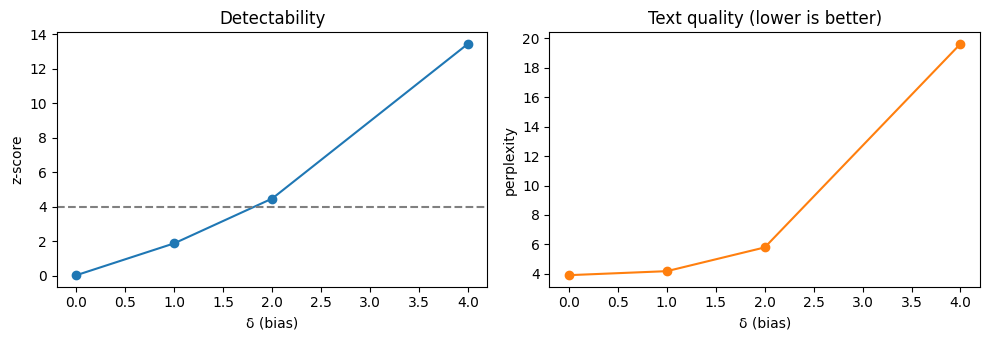

In [ ]:
@torch.no_grad()
def perplexity(prompt, ids):
    # perplexity of the generated tokens under the original model, given the prompt
    p = tok(chat_prompt(prompt), return_tensors="pt")["input_ids"][0]
    full = torch.cat([p, ids]).unsqueeze(0).to(device)
    logits = model(full).logits[0, len(p) - 1 : -1].float()
    nll = torch.nn.functional.cross_entropy(logits, full[0, len(p):])
    return math.exp(nll.item())

prompts = [PROMPT, "Explain to a 12-year-old why the sky is blue.", "Describe a good breakfast in three sentences."]
deltas = [0.0, 1.0, 2.0, 4.0]
rows = []
for d in deltas:
    w = GreenListWatermark(model.config.vocab_size, gamma=0.25, delta=d)
    zs, ppls = [], []
    for i, p in enumerate(prompts):
        ids = generate(p, watermark=w if d > 0 else None, max_new_tokens=100, seed=i)
        zs.append(detect(ids, w)["z"]); ppls.append(perplexity(p, ids))
    rows.append((d, sum(zs) / len(zs), sum(ppls) / len(ppls)))
    print(f"δ = {d:<4}  mean z = {rows[-1][1]:6.2f}   mean perplexity = {rows[-1][2]:6.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot([r[0] for r in rows], [r[1] for r in rows], "o-"); ax[0].axhline(4, ls="--", c="gray")
ax[0].set(xlabel="δ (bias)", ylabel="z-score", title="Detectability")
ax[1].plot([r[0] for r in rows], [r[2] for r in rows], "o-", c="tab:orange")
ax[1].set(xlabel="δ (bias)", ylabel="perplexity", title="Text quality (lower is better)")
plt.tight_layout(); plt.show()

You should see z climb quickly with δ while perplexity rises more slowly. Around δ ≈ 2 is a common sweet spot. (With only three short samples the curves are noisy — the trend is what matters.)

## 7 · Trade-off 2: how much text do we need?

The z-score grows roughly with $\sqrt{T}$: every extra token adds a bit of evidence. Let's score growing prefixes of the watermarked text.

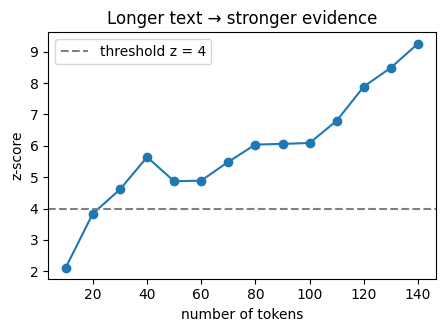

In [ ]:
lengths = list(range(10, len(wm_ids), 10))
z_by_len = [detect(wm_ids[:n], wm)["z"] for n in lengths]

plt.figure(figsize=(5, 3.2))
plt.plot(lengths, z_by_len, "o-"); plt.axhline(4, ls="--", c="gray", label="threshold z = 4")
plt.xlabel("number of tokens"); plt.ylabel("z-score"); plt.title("Longer text → stronger evidence"); plt.legend()
plt.show()

Short answers ("Yes.", a 10-token reply, a line of code) simply do not carry enough evidence. This is a fundamental limit, not a bug in our code.

## 8 · Trade-off 3: robustness to edits

What if someone edits the text? Each token's color depends on the token **before** it, so changing one token can break two green/red decisions. Let's replace a growing share of tokens with random ones and watch z.

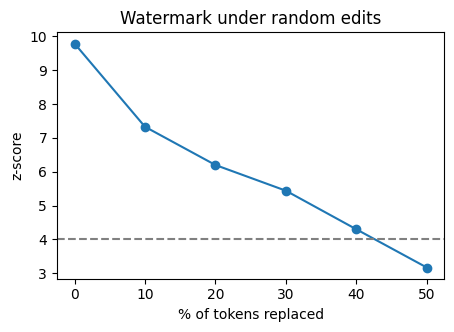

In [ ]:
def random_edit(ids, share, seed=0):
    rng = random.Random(seed)
    ids = ids.clone()
    for i in rng.sample(range(len(ids)), int(share * len(ids))):
        ids[i] = rng.randrange(len(tok))
    return ids

shares = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
z_edit = [detect(random_edit(wm_ids, s), wm)["z"] for s in shares]

plt.figure(figsize=(5, 3.2))
plt.plot([int(s * 100) for s in shares], z_edit, "o-"); plt.axhline(4, ls="--", c="gray")
plt.xlabel("% of tokens replaced"); plt.ylabel("z-score"); plt.title("Watermark under random edits")
plt.show()

The watermark survives a fair amount of local editing — the signal is spread across the whole text. Random replacement is a crude attack, though. A smarter one is to **rewrite everything**.

## 9 · Paraphrasing attack

We ask the same model — this time **without** the watermark — to paraphrase the watermarked text, and then run the detector again.

In [ ]:
wm_text = tok.decode(wm_ids, skip_special_tokens=True)
para_ids = generate("Paraphrase the following text, keeping its meaning:\n\n" + wm_text, max_new_tokens=180, seed=1)

print(tok.decode(para_ids, skip_special_tokens=True))
print("\noriginal watermarked:", detect(wm_ids, wm))
print("after paraphrasing:  ", detect(para_ids, wm))
display(HTML(color_tokens(para_ids, wm)))

Previous responses regarding the roles of lighthouses in navigating on the Aegean Sea coast have piqued your interest. The contemporary utilization of lighthouses in recent years aligns with the technological advancements seen during the ages preceding this era. The emergence of maritime technology allowed for improvements in lighthouse construction methods.

The utilization of lumber hammers was prevalent during the Middle Ages when lighthouses were not commonly found and relied heavily on wind and tide patterns for operation. However, advancements in shipbuilding techniques transformed traditional structures into more robust ones, thereby facilitating improved lighthouse functionality.

A significant change came about with the advent of galleons. These vessels quickly gained prominence due to their increased versatility as sea transport tools, necessitating them to develop superior tracking and navigation skills beyond those needed for merchant ships of olden days. As a result, light

After paraphrasing, the share of green tokens usually falls back towards γ and z drops below the threshold: the meaning survived, the watermark did not. This is the main weakness of text watermarks — and the reason research continues on more robust schemes.

## 10 · The built-in version in 🤗 transformers

You don't have to write it yourself. `transformers` ships the same family of watermarks, including a variant (`selfhash`) that is harder to reverse-engineer.

In [ ]:
from transformers import WatermarkingConfig, WatermarkDetector

wm_config = WatermarkingConfig(bias=2.5, seeding_scheme="selfhash")
inputs = tok(chat_prompt(PROMPT), return_tensors="pt").to(device)
out = model.generate(**inputs, watermarking_config=wm_config, do_sample=True, max_new_tokens=150, pad_token_id=tok.eos_token_id)

detector = WatermarkDetector(model_config=model.config, device=device, watermarking_config=wm_config)
result = detector(out[:, inputs["input_ids"].shape[1]:], return_dict=True)
print("z-score:", result.z_score, "→ watermarked:", result.prediction)

z-score: [4.6197643] → watermarked: [ True]


## 11 · What we saw, and where to go next

- A watermark is a **statistical signal hidden in token choices**, keyed by a secret.
- Detection is a simple **z-test** that needs only the tokenizer and the key.
- There are real trade-offs: **strength vs quality**, and **length** — short texts can't be reliably marked.
- **Local edits** barely hurt it; **paraphrasing** largely removes it.

The lecture covered what happens beyond this toy example:

- **SynthID-Text** (Google DeepMind, Nature 2024) — tournament sampling, deployed in Gemini.
- **Watermark stealing** (Jovanović et al., ICML 2024) — an attacker can learn the green lists from API outputs, then spoof or scrub for under $50.
- **Open-source models** (Gloaguen et al., 2025; Scharff et al., NeurIPS 2026) — a watermark in the sampler is easy to switch off, so it has to live in the weights and survive fine-tuning and merging.

**Things to try if you have a few more minutes:** change γ, change the secret key and re-run detection (z collapses — you need the right key), or watermark a text in Ukrainian and check whether detection works just as well.

*Reading:* [Kirchenbauer et al., 2023](https://arxiv.org/abs/2301.10226) · [Watermark stealing](https://watermark-stealing.org) · [Towards watermarking of open-source LLMs](https://arxiv.org/abs/2502.10525)